In [1]:
# rsync -av --progress /scratch/franzihe/input/COMBLE u6030275@notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data 

# rsync -av --progress login.nird.sigma2.no:/projects/NS9600K/data/Met-No_obs/  /uio/kant/geo-metos-u1/franzihe/Documents/input/Met-No_obs

In [2]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/"
if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"

INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

# make output file directory
nc_dir = os.path.join(OUTPUT_DATA_DIR, 'ANX_obs')
try:
    new_dir = pathlib.Path(nc_dir)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

mimi.uio.no


## Import python packages

* `Python` environment requirements: file requirements_retrieval.txt
* load `python` packages from imports.py
* load `functions` from functions.py



In [3]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt, np, DateFormatter, datetime, cm, pd, da, IMProToo,LinearSegmentedColormap, BoundaryNorm, time, curve_fit)
# from matplotlib.collections import PathCollection
import functions as fct
version = IMProToo.__version__


In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
sites = ["ANX", ]#"ALOMAR"]
years = [#"2021","2022",
         "2023"]

In [6]:
mrr_in_dict, ds_dict_mrr = {}, {}
met_dict_t, met_dict_wd, met_dict_ws, met_dict_p = {}, {}, {}, {}
ds_dict_met_t, ds_dict_met_wd, ds_dict_met_ws, ds_dict_met_p = {}, {}, {}, {}
# ceil_in_dict, ds_dict_ceil = {}, {}
snowflake_class_in_dict, ds_dict_snowflake_class = {}, {}
# graupel_in_dict, ds_dict_graupel = {}, {}
# aggregate_in_dict, ds_dict_aggregate = {}, {}
# small_particle_in_dict, ds_dict_small_particle = {}, {}
# planar_crystal_in_dict, ds_dict_planar_crystal = {}, {}
# columnar_crystal_in_dict, ds_dict_columnar_crystal = {}, {}
# columnar_planar_in_dict, ds_dict_columnar_planar = {}, {}


In [7]:
dicts_to_clean = [ds_dict_mrr,#ds_dict_ceil, 
                  ds_dict_snowflake_class, ds_dict_met_t,ds_dict_met_wd,ds_dict_met_ws,ds_dict_met_p]

In [8]:
met_no_dict = {}
ds_dict_metno = {}



for site in sites:
    for year in years:
        key = f'{site}.{year}'
        
        # Collect file paths
        mrr_in_dict[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'MRR_ANX/maahn/mrr_improtoo*_{site}_{year}*.nc')))
        # ceil_in_dict[key]   = sorted(glob(os.path.join(INPUT_DATA_DIR, f'ceilometer/combined/bsc_cbh_{year}*.nc')))
        snowflake_class_in_dict[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'MASC_DB/t_2degC/*{year}_most_common_class_1min_0.6.nc')))

        # hatpro_in_dict[f'{site}.{year}'] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/{year}/*/*/*{year}*.nc')))
        
        # Met data handling
        # met_no_dict['{}.{}'.format(site, year)] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110/*{}*'.format(year))))
        if year in ["2021",]:
            met_dict_t[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/air_temperature_{year}*.nc')))
        if year == "2022":
            met_dict_t[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, 'tinytag/TGP-4505_917173.nc')))
        if year == "2023":
            met_dict_t[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/hatpro_new_20240716/level1/{year}/*/*/*.nc')))
            # # met_dict_wd[key]   = sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/hatpro_new_20240716/level1/{year}/*/*/*.nc')))
            # # met_dict_ws[key]   = sorted(glob(os.path.join(INPUT_DATA_DIR, f'hatpro/hatpro_new_20240716/level1/{year}/*/*/*.nc')))
            # # met_dict_t[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/air_temperature_{year}*.nc')))
            met_dict_wd[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/ANX_wind_10min_to_1min_filled_{year}.nc')))
            met_dict_ws[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/ANX_wind_10min_to_1min_filled_{year}.nc')))
            met_dict_p[key]    = sorted(glob(os.path.join(INPUT_DATA_DIR, f'geonor/precip_*.nc')))
        if year in ['2021', '2022',]:
            met_dict_wd[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/wind_from_direction_{year}*.nc')))
            met_dict_ws[key] = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/wind_speed_{year}*.nc')))
            met_dict_p[key]  = sorted(glob(os.path.join(INPUT_DATA_DIR, f'Met-No_obs/SN87110/*sum(precipitation_amount PT1H)_{year}*')))
        
        # Open or initialize Datasets
        ds_dict_mrr[key]        = fct.open_or_empty(mrr_in_dict[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        # ds_dict_ceil[key]       = fct.open_or_empty(ceil_in_dict[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        ds_dict_snowflake_class[key] = fct.open_or_empty(snowflake_class_in_dict[key], decode_times=True, preprocess=lambda x: x.sortby('time'))

        ds_dict_met_t[key]      = fct.open_or_empty(met_dict_t[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        ds_dict_met_wd[key]     = fct.open_or_empty(met_dict_wd[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        ds_dict_met_ws[key]     = fct.open_or_empty(met_dict_ws[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        ds_dict_met_p[key]      = fct.open_or_empty(met_dict_p[key], decode_times=True, preprocess=lambda x: x.sortby('time'))
        
        
        # for ds_dict in dicts_to_clean:
        #     if key in ds_dict: # just in case key is missing
        #         ds = ds_dict[key].copy()
        #         if 'time' in ds.dims and ds.sizes['time'] > 0:
        #             ds_dict[key] = ds.dropna(dim='time')
        # #             ds_dict[key] = ds.sel(time=~ds.indexes['time'].duplicated('first'))
        

In [9]:
base_height = np.arange(100,3200, 100) # Predefined MRR profile


In [10]:
# target_dates = {'20210317',}# '20220322', '20230225'}
# target_dates = {'20230215', '20230216','20230217','20230218','20230219','20230220','20230221','20230222','20230223','20230224','20230225','20230226','20230227','20230228','20230301','20230302','20230303','20230305','20230306','20230307','20230308','20230309','20230310','20230311','20230312','20230313','20230314'}
target_dates = {'20230301',}
start = time.time()
for key in list(mrr_in_dict.keys()):
    site, year = key.split('.')
    
    for j, file_path in enumerate(mrr_in_dict[key]):
        date = file_path[-11:-3]
        # if date not in target_dates:
        #     continue  # Skip dates not in the target list
        
        
        
        print(f"Reading file for {site}, {date}...")
        figname = f'mrr_reflectivity_{site}_{date}.png'
        # file_out = os.path.join(OUTPUT_DATA_DIR, f'MRR_ANX/bin_averaged/mrr_improtoo_{version}_{site}_{date}.nc')
        # pathlib.Path(os.path.dirname(file_out)).mkdir(parents=True, exist_ok=True)
        
        # filename = f"obs_{site}_{date}.nc"
        # filename = f"obs_airport_WD_WS_T_{site}_{date}.nc"
        # filename = f"obs_hatpro_airport_WD_WS_T_{site}_{date}.nc"
        filename = f"10min_filled_obs_hatpro_airport_WD_WS_T_{site}_{date}.nc"
        
        # Define start and end time of individual day
        day_start = pd.Timestamp(f"{date} 00:00:00")
        day_end = day_start + pd.Timedelta(hours=23, minutes=59)
        _xmax = day_start + pd.Timedelta(hours=24)
        _time = pd.date_range(start=day_start, periods=1440, freq='min')
        # Create 5-min interval time range for that day
        times = pd.date_range(start=day_start, end=day_end, freq='5min', )#closed='left')

        # create new dataset with NaNs and time resolution 1 minute
        dsx = xr.Dataset(data_vars=dict(
            air_temperature =(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
            wind_direction  =(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
            wind_speed      =(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
            precipitation   =(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
            Ze              =(["time","range"], da.full(shape= (len(_time),len(ds_dict_mrr[key].range)), fill_value = np.nan)),
            W               =(["time","range"], da.full(shape= (len(_time),len(ds_dict_mrr[key].range)), fill_value = np.nan)),
            height          =(["range"], base_height),
            spectralWidth   =(["time","range"], da.full(shape= (len(_time),len(ds_dict_mrr[key].range)), fill_value = np.nan)),
            # bsc             =(["time","altitude"], da.full(shape=(len(_time), len(ds_dict_ceil[key].altitude)), fill_value=np.nan)),
            # cbh             =(["time"], np.full(shape=(len(_time),), fill_value=np.nan)),
            most_common_class = (["time"], np.full(shape=(len(_time),), fill_value=np.nan, dtype=object)),
            aggregate = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            graupel = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            pristine = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            mixed = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            wind_sector_8 = (["time"], np.full(shape=(len(_time),), fill_value=np.nan, dtype=object)),
            wind_sector_16 = (["time"], np.full(shape=(len(_time),), fill_value=np.nan, dtype=object)),
            riming_deg_level = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Matrosov_aggregate = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Bracci_aggregate = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Nakai_aggregate = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Nakai_graupel = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
            Pu_graupel = (["time"], np.full(shape=(len(_time),), fill_value=np.nan,)),
        ),
                         coords=dict(
                             time       =_time,
                             range      =ds_dict_mrr[key].range.values,
                            #  altitude   =ds_dict_ceil[key].altitude.values
                             ))
        

        
# Variable names per year
        # if year in ['2021', '2022', '2023']:
        if year == '2021':
                var_id_t    = 'air_temperature'
                var_id_wd   = 'wind_from_direction'
                var_id_pp   = 'sum(precipitation_amount PT1H)'
                var_id_ws   = 'wind_speed'
        elif year == '2022':
                var_id_t    = 'TA'
                var_id_wd   = 'wind_from_direction'
                var_id_pp   = 'sum(precipitation_amount PT1H)'
                var_id_ws   = 'wind_speed'
        elif year == '2023':
                var_id_t    = 'air_temperature'
                # var_id_wd   = 'wind_direction'
                var_id_wd   = 'wind_direction_filled'
                var_id_pp   = 'precipitation'
                var_id_ws   = 'wind_speed_filled'
        _air_temp   = ds_dict_met_t[key][var_id_t].sel(time = slice(day_start, day_end))
        _wd         = ds_dict_met_wd[key][var_id_wd].sel(time = slice(day_start, day_end))
        _ws         = ds_dict_met_ws[key][var_id_ws].sel(time = slice(day_start, day_end))
        _pp         = ds_dict_met_p[key][var_id_pp].sel(time = slice(day_start, day_end))
        # elif year in ['2023']:
        #     _air_temp   = ds_dict_snowflake_class[key]['env_T_test'].sel(time = slice(day_start, day_end))
        #     _wd         = ds_dict_snowflake_class[key]['env_DD_test'].sel(time = slice(day_start, day_end))
        #     _ws         = ds_dict_snowflake_class[key]['env_FF_test'].sel(time = slice(day_start, day_end))
        #     _pp         = ds_dict_met_p[key]['precipitation'].sel(time = slice(day_start, day_end))
        
        
        ####
        # # read Ceilometer data
        # _bsc    = ds_dict_ceil[key]['bsc'].sel(time = slice(day_start, day_end))#.rename({"range":"height_c"})
        # _cbh    = ds_dict_ceil[key]['cbh'].sel(time = slice(day_start, day_end))
        
        # read MRR data
        _Ze     = ds_dict_mrr[key]['Ze'].sel(time = slice(day_start, day_end))
                
        _W      = (ds_dict_mrr[key]['W'].sel(time = slice(day_start, day_end)))*(-1)
        _W      = _W.where(_Ze>=-20.)
        
        _sWidth = ds_dict_mrr[key]['spectralWidth'].sel(time = slice(day_start, day_end))
        _sWidth = _sWidth.where(_Ze>=-20.)
        
        _M_agg = ds_dict_mrr[key]['Matrosov_aggregate'].sel(time = slice(day_start, day_end))
        _B_agg = ds_dict_mrr[key]['Bracci_aggregate'].sel(time = slice(day_start, day_end))
        _N_agg = ds_dict_mrr[key]['Nakai_aggregate'].sel(time = slice(day_start, day_end))
        _N_gra = ds_dict_mrr[key]['Nakai_graupel'].sel(time = slice(day_start, day_end))
        _P_gra = ds_dict_mrr[key]['Pu_graupel'].sel(time = slice(day_start, day_end))
        
        # read MASCDB data
        if 'snowflake_class_name' in ds_dict_snowflake_class[key]:
            most_common_class = ds_dict_snowflake_class[key]['snowflake_class_name'].sel(time=slice(day_start, day_end))
            aggregate = ds_dict_snowflake_class[key]['aggregate'].sel(time=slice(day_start, day_end))
            graupel = ds_dict_snowflake_class[key]['graupel'].sel(time=slice(day_start, day_end))
            pristine = ds_dict_snowflake_class[key]['pristine'].sel(time=slice(day_start, day_end))
            wind_dir_sector_8 = ds_dict_snowflake_class[key]['wind_direction_sector'].sel(time=slice(day_start, day_end))
            wind_dir_sector_16 = ds_dict_snowflake_class[key]['compass'].sel(time=slice(day_start, day_end))
            riming_deg_level = ds_dict_snowflake_class[key]['riming_deg_level'].sel(time=slice(day_start, day_end))
        else:
            # Create NaN DataArray
            most_common_class            = fct.empty_class_array('most_common_class', times)
            aggregate = fct.empty_class_array('aggregate', times)
            graupel = fct.empty_class_array('graupel', times)
            pristine = fct.empty_class_array('pristine', times)
            wind_dir_sector_8 = fct.empty_class_array('wind_dir_sector_8', times)
            wind_dir_sector_16 = fct.empty_class_array('wind_dir_sector_16', times)
            riming_deg_level = fct.empty_class_array('riming_deg_level', times)
            print(f"'most_common_class' not found in dataset: {key}")    
            
        if 'mixed' in ds_dict_snowflake_class[key]:
            mixed = ds_dict_snowflake_class[key]['mixed'].sel(time=slice(day_start, day_end)) 
        else: 
            mixed = fct.empty_class_array('mixed', times)
        
        
# minutely averaged ceilometer data
        # _bsc  = _bsc.resample(time='1min').mean('time', skipna=True, keep_attrs=True)
        # _cbh  = _cbh.resample(time='1min').mean('time', skipna=True, keep_attrs=True)
        
        # # Hourly accumulated precipitation
        # if len(_pp) != 0:
        #     _pp    = _pp.resample(time='1H').sum('time', skipna=True, keep_attrs=True)
        
        

        # if year == '2023' and len(_air_temp) != 0:
        #     _air_temp = _air_temp.resample(time='10min').mean('time', skipna=True, keep_attrs=True)
        
        # Fill values to minutely data using function
        dsx['air_temperature']  = fct.arrays_same_time_res(_air_temp, dsx['air_temperature'])
        dsx['wind_direction']   = fct.arrays_same_time_res(_wd, dsx['wind_direction'])
        dsx['wind_speed']       = fct.arrays_same_time_res(_ws, dsx['wind_speed'])
        dsx['precipitation']    = fct.arrays_same_time_res(_pp, dsx['precipitation'])
        dsx['Ze']               = fct.arrays_same_time_res(_Ze, dsx['Ze'])
        dsx['W']                = fct.arrays_same_time_res(_W, dsx['W'])
        dsx['spectralWidth']    = fct.arrays_same_time_res(_sWidth, dsx['spectralWidth'])
        dsx['most_common_class']= fct.arrays_same_time_res(most_common_class, dsx['most_common_class'])
        dsx['aggregate']        = fct.arrays_same_time_res(aggregate, dsx['aggregate'])
        dsx['graupel']          = fct.arrays_same_time_res(graupel, dsx['graupel'])
        dsx['pristine']         = fct.arrays_same_time_res(pristine, dsx['pristine'])
        dsx['mixed']            = fct.arrays_same_time_res(mixed, dsx['mixed'])
        dsx['wind_sector_8']    = fct.arrays_same_time_res(wind_dir_sector_8, dsx['wind_sector_8'])
        dsx['wind_sector_16']   = fct.arrays_same_time_res(wind_dir_sector_16, dsx['wind_sector_16'])
        dsx['riming_deg_level'] = fct.arrays_same_time_res(riming_deg_level, dsx['riming_deg_level'])
        dsx['Matrosov_aggregate'] = fct.arrays_same_time_res(_M_agg, dsx['Matrosov_aggregate'])
        dsx['Bracci_aggregate'] = fct.arrays_same_time_res(_B_agg, dsx['Bracci_aggregate'])
        dsx['Nakai_aggregate']  = fct.arrays_same_time_res(_N_agg, dsx['Nakai_aggregate'])
        dsx['Nakai_graupel']    = fct.arrays_same_time_res(_N_gra, dsx['Nakai_graupel'])
        dsx['Pu_graupel']       = fct.arrays_same_time_res(_P_gra, dsx['Pu_graupel'])
        
        # extract Ze at 400 m for Z-S relationship
        dsx['Ze_400m'] = dsx['Ze'].isel(range=3).drop("range")
        dsx['Ze_linear'] = 10 ** (dsx['Ze_400m']/10)
        dsx['Ze_linear'].name = "Ze_linear"

        
# Assign variable attributes
        for name, var in zip(['air_temperature', 'wind_direction', 'wind_speed', 'precipitation', 'Ze', 'W', 'spectralWidth', 'Matrosov_aggregate', 'Bracci_aggregate', 'Nakai_aggregate', 'Nakai_graupel', 'Pu_graupel'
                            #   'bsc', 'cbh'
                              ], [_air_temp, _wd, _ws, _pp, _Ze, _W, _sWidth, _M_agg, _B_agg, _N_agg, _N_gra, _P_gra #_bsc, _cbh
                                                                                                                                              ]):
            dsx[name].attrs = var.attrs

        
        
        # test if temperature has same units and assign degC
        units = dsx['air_temperature'].attrs.get('units', '').lower()
        # Check and convert if in Kelvin
        if 'kelvin' in units or 'k' in units:
            print(f"⚠️ Air temperature is in Kelvin. Converting to Celsius... {date}")
            dsx['air_temperature'] = dsx['air_temperature'] - 273.15
            dsx['air_temperature'].attrs['units'] = 'Celsius'
            dsx['air_temperature'].attrs['note'] = 'Converted from Kelvin to Celsius'
        elif 'celsius' in units or 'degc' in units or 'degree_celsius' in units or 'degree_c' in units:
            print(f"✅ Air temperature is already in Celsius. {date}")
        else:
            print(f"❓ Unrecognized units: {units} (no conversion applied). {date}")

        # make units same format
        dsx['W'].attrs['units'] = 'm/s'
        dsx['precipitation'].attrs['units'] = 'mm'
        dsx['air_temperature'].attrs['units'] = '$^{\circ}$C'
        dsx['wind_direction'].attrs['units'] = '$^{\circ}$'
        dsx['Ze_400m'].attrs['units'] = dsx['Ze'].units
        dsx['Ze_400m'].attrs['description'] = 'Reflectivity extracted at range bin = 3 -> @400m'
        dsx['Ze_linear'].attrs['units'] = 'mm^6 m^-3'
        dsx['Ze_linear'].attrs['description'] = 'Reflectivity transformed to linear units, extracted at range bin = 3 -> @400m'


        
        
        # assign attributes to Dataset
        dsx = dsx.assign_attrs({'title': 'Micro rain radar data processed with IMProToo and bin averaged',
                                'comment': ds_dict_mrr[key].attrs['comment'],
                                'institution': ds_dict_mrr[key].attrs['institution'],
                                'contact_person': ds_dict_mrr[key].attrs['contact_person'],
                                'source': ds_dict_mrr[key].attrs['source'],
                                'location': ds_dict_mrr[key].attrs['location'],
                                'history': ds_dict_mrr[key].attrs['history'],
                                'processing_date': ds_dict_mrr[key].attrs['processing_date'],
                                'reference': ds_dict_mrr[key].attrs['reference'],
                                'mrrHeader': ds_dict_mrr[key].attrs['mrrHeader']})
        
        
        # plt_Ze_W_p_T_U(dsx, day_start, _xmax, key)
        
        # # save image to png
        # plt.savefig(FIG_DIR + figname, format='png', bbox_inches='tight', transparent=True,dpi=300)
        
        # dsx.to_netcdf(os.path.join(nc_dir, filename))
        # loop over one file
        print("Elapsed time: {:.2f} seconds".format(time.time() - start))

Reading file for ANX, 20230212...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230212
Elapsed time: 0.24 seconds
Reading file for ANX, 20230213...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230213
Elapsed time: 0.32 seconds
Reading file for ANX, 20230214...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230214
Elapsed time: 0.39 seconds
Reading file for ANX, 20230215...


⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230215
Elapsed time: 0.47 seconds
Reading file for ANX, 20230216...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230216
Elapsed time: 0.55 seconds
Reading file for ANX, 20230217...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230217
Elapsed time: 0.63 seconds
Reading file for ANX, 20230218...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230218
Elapsed time: 0.71 seconds
Reading file for ANX, 20230219...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230219
Elapsed time: 0.80 seconds
Reading file for ANX, 20230220...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230220
Elapsed time: 0.89 seconds
Reading file for ANX, 20230221...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230221
Elapsed time: 0.97 seconds
Reading file for ANX, 20230222...
⚠️ Air temperature is in Kelvin. Converting to Celsius... 20230222
Elapsed time: 1.05 seconds
Reading fi

In [11]:
ds_23 = xr.open_mfdataset(sorted(glob(os.path.join(nc_dir, '10min_filled_obs_hatpro_airport_WD_WS_T_ANX_2023*.nc'))))

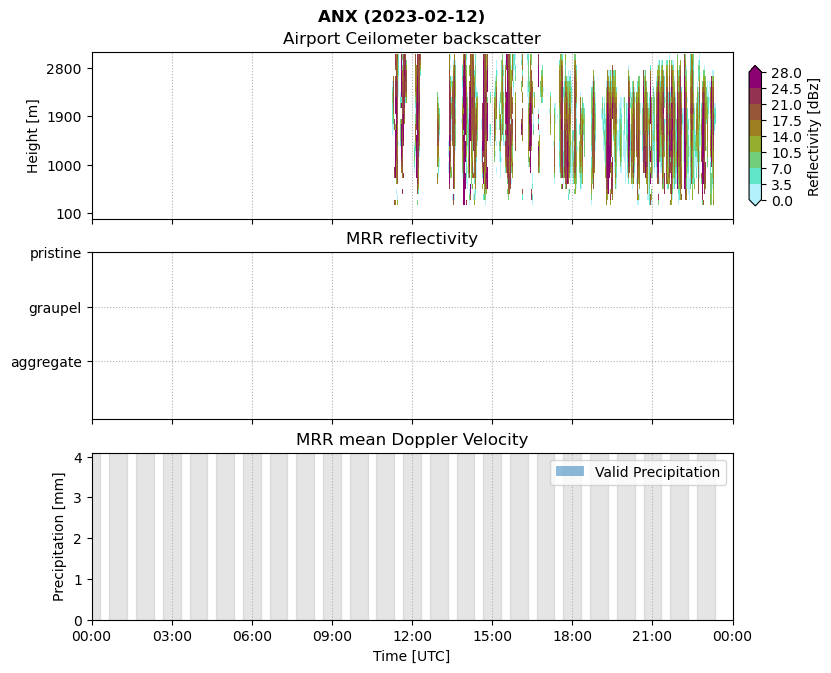

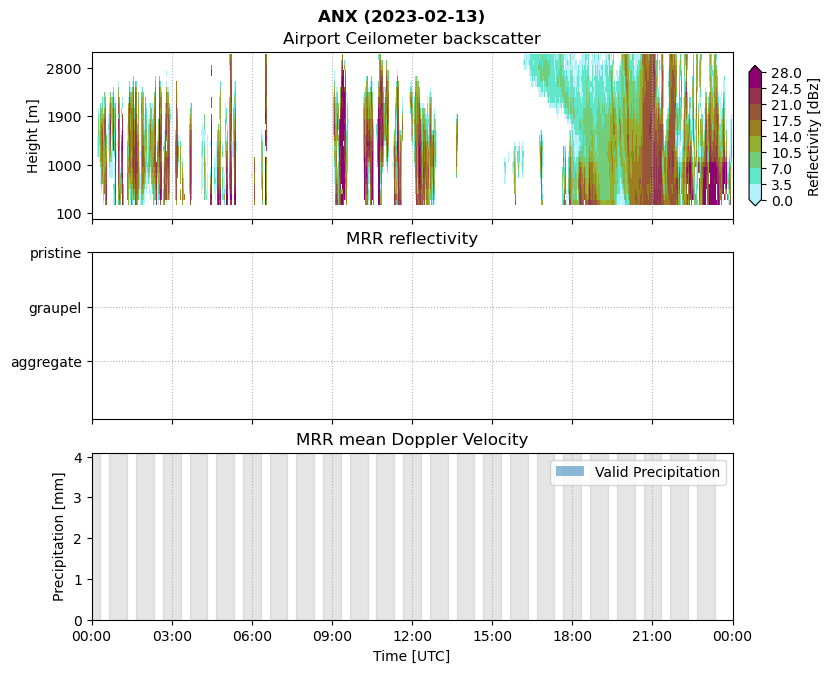

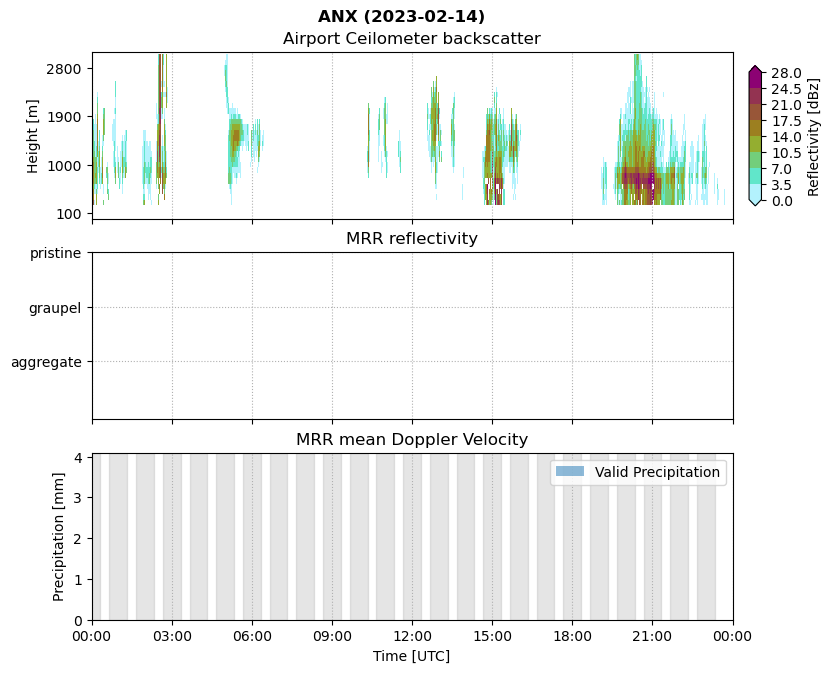

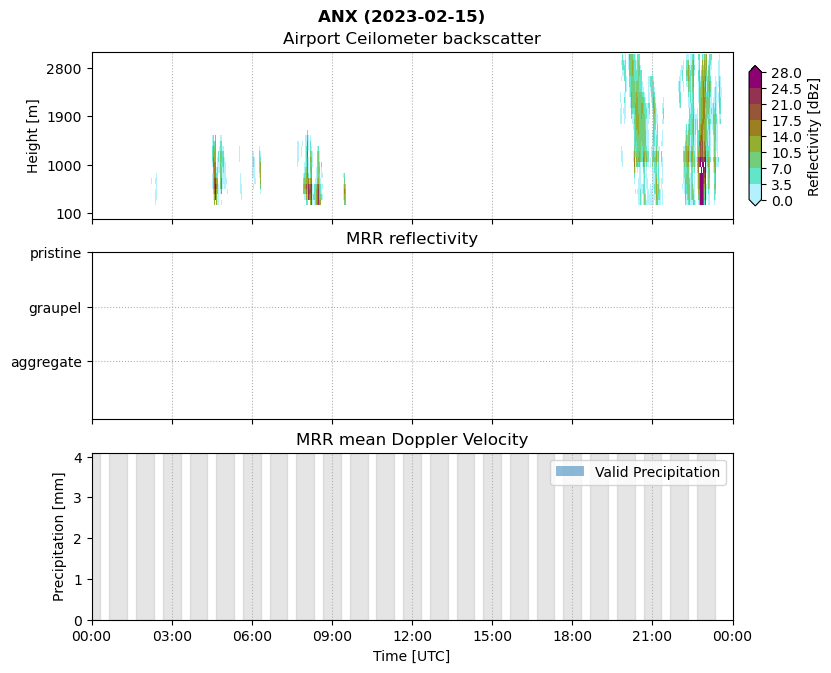

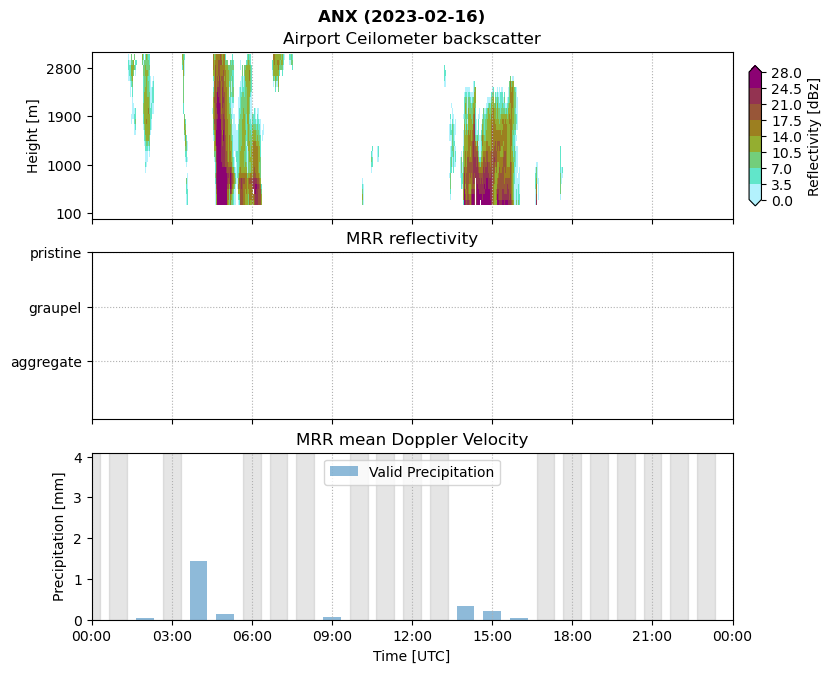

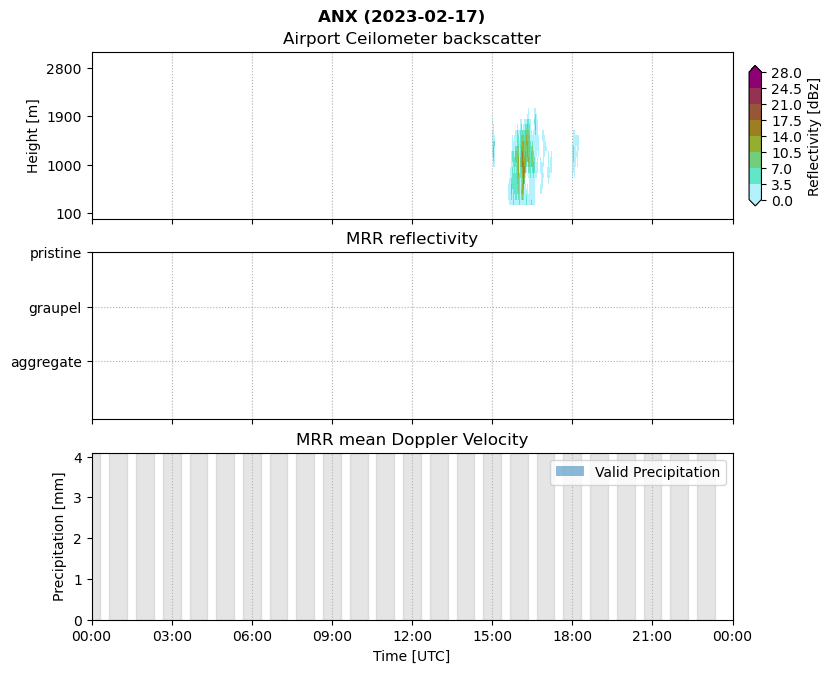

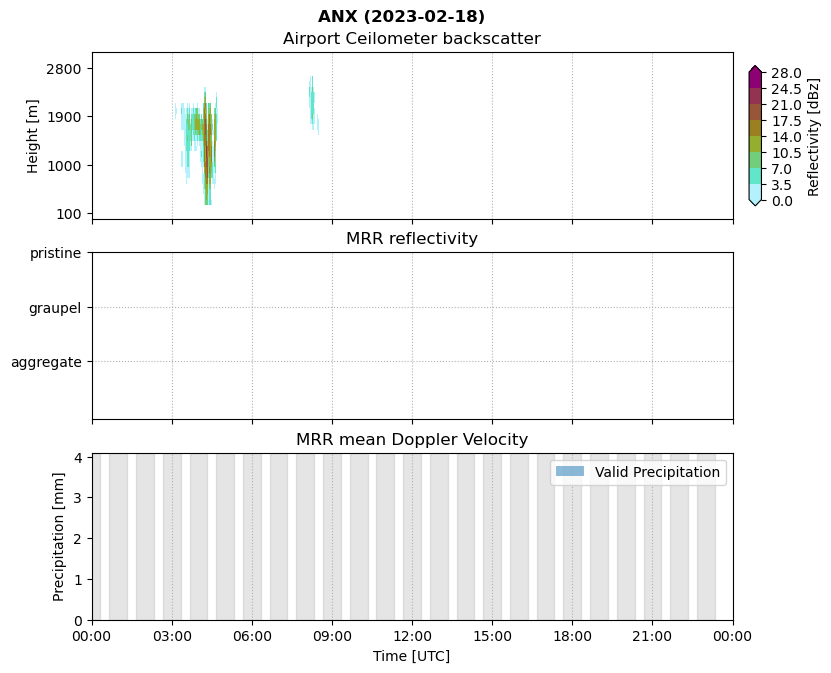

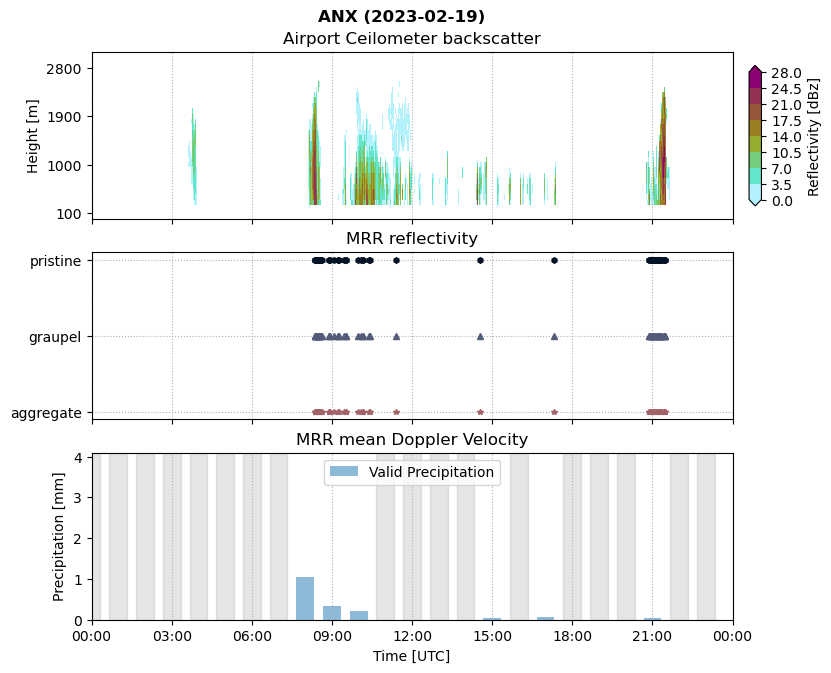

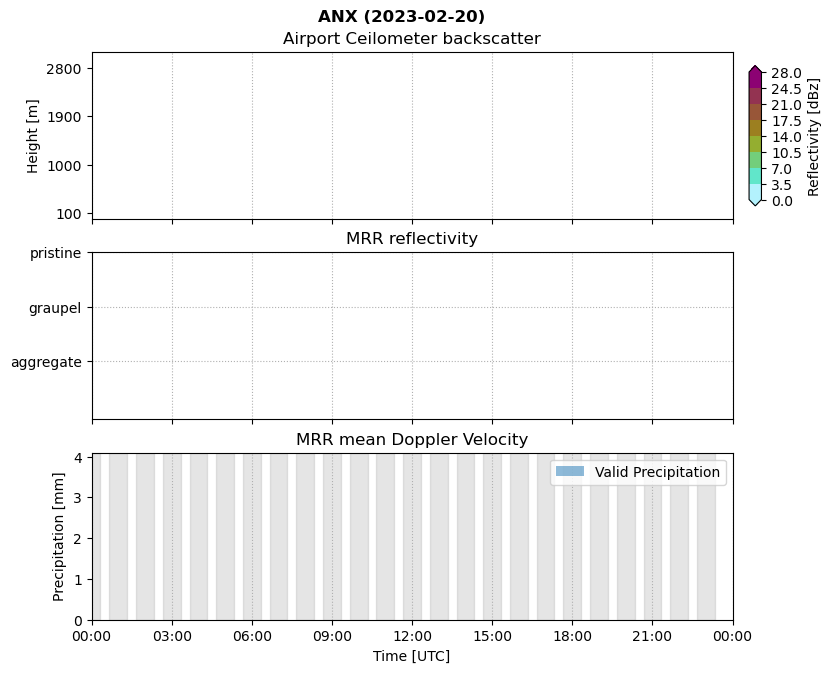

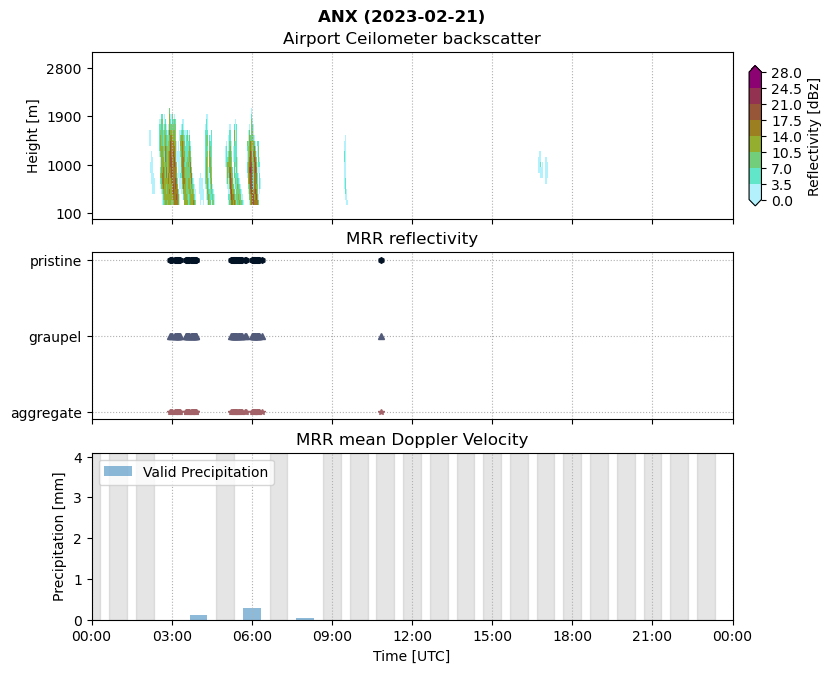

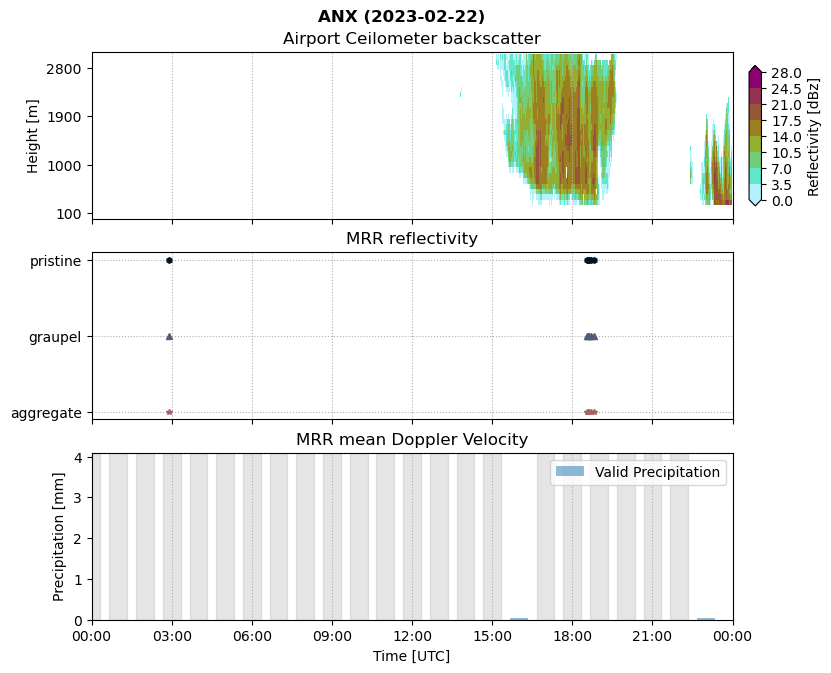

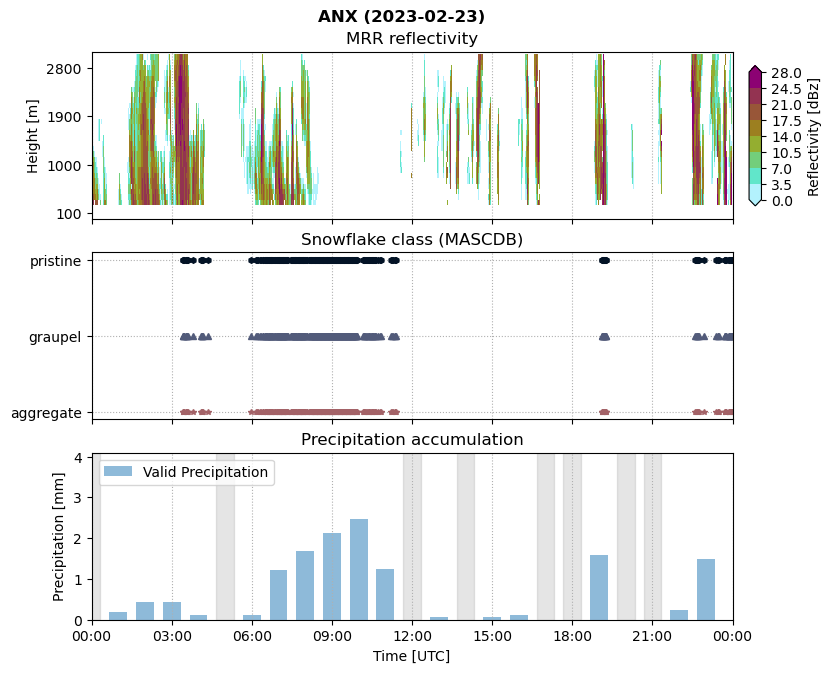

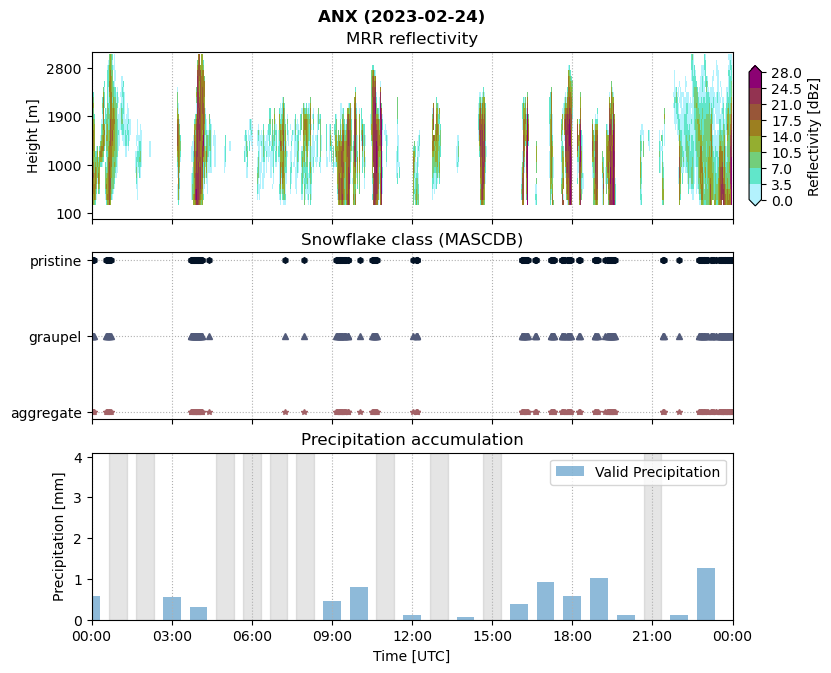

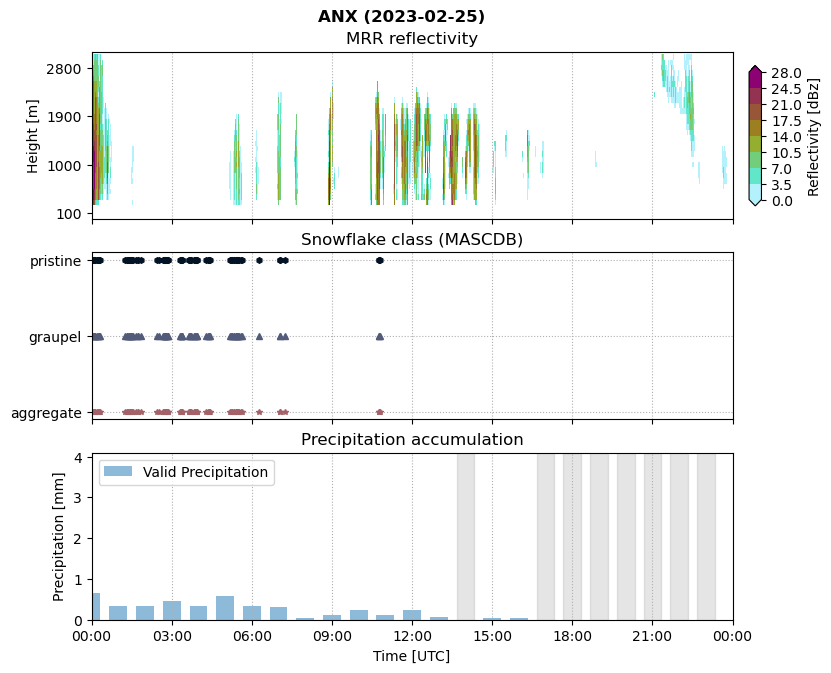

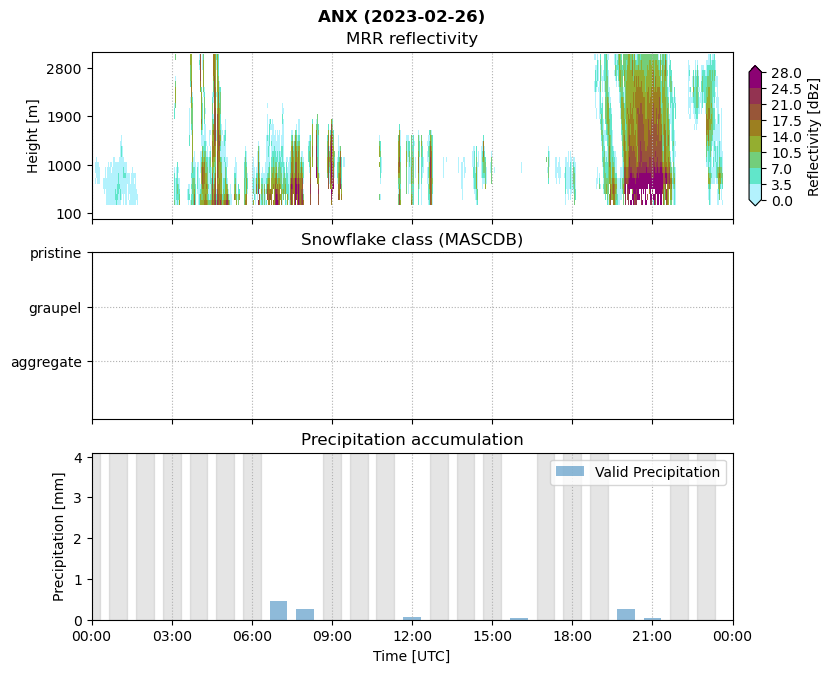

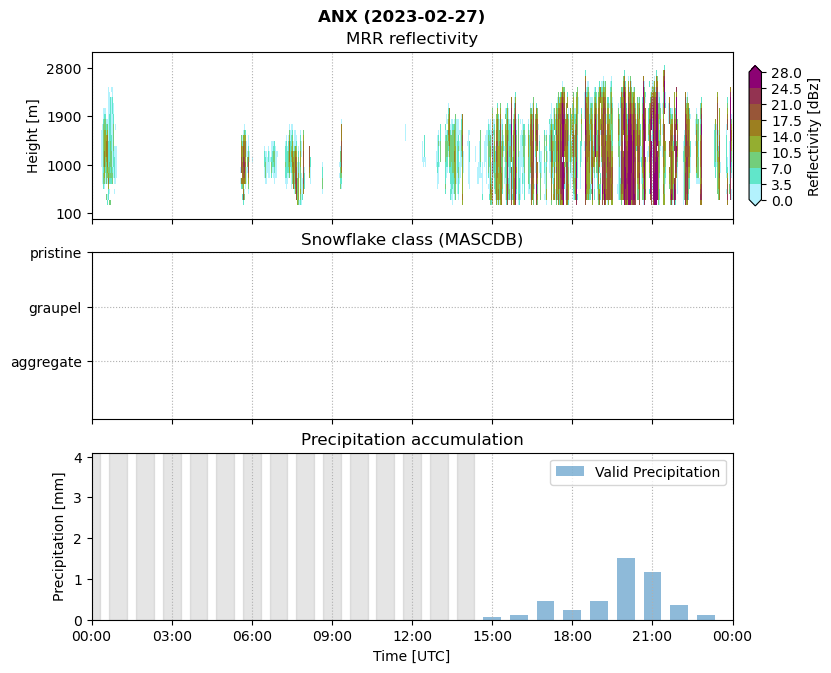

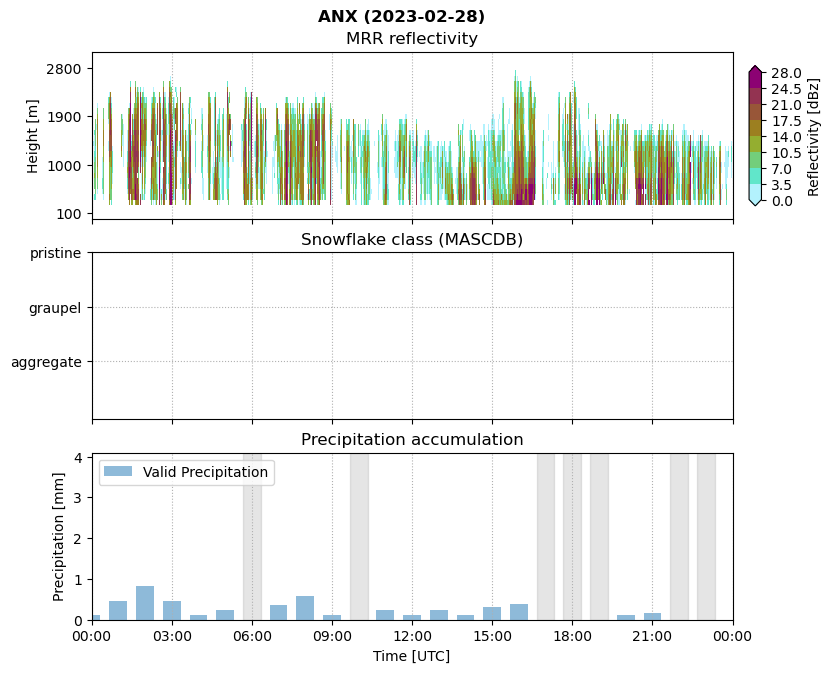

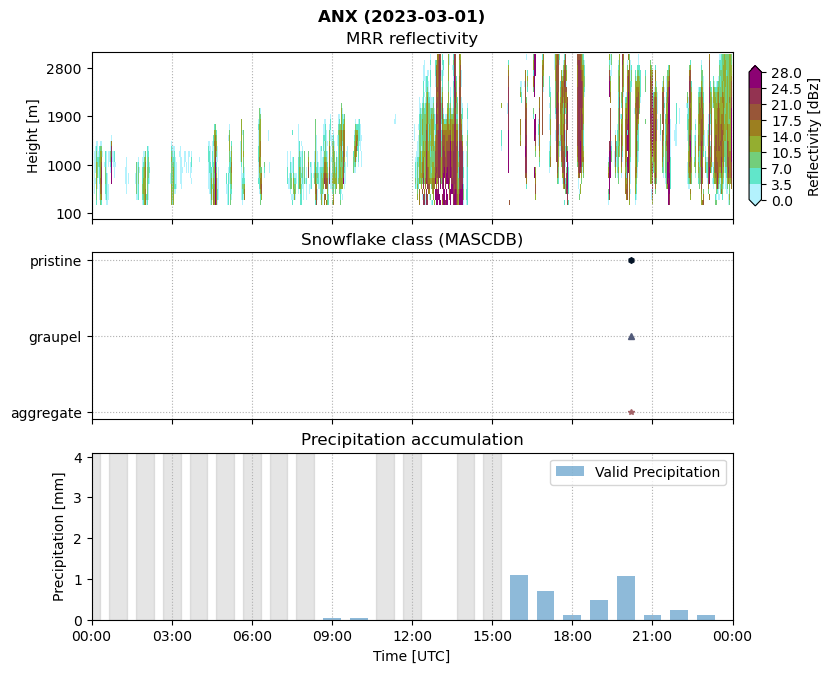

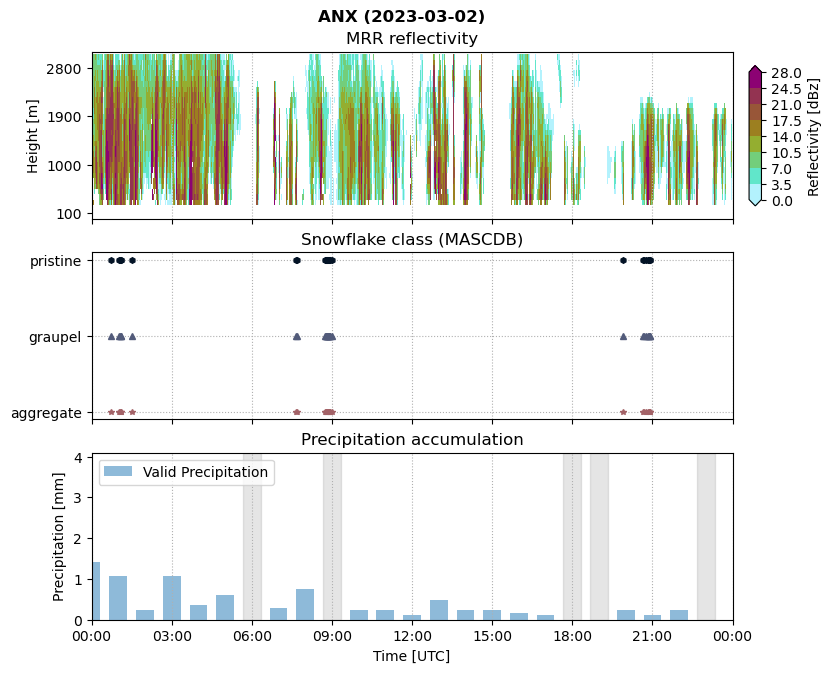

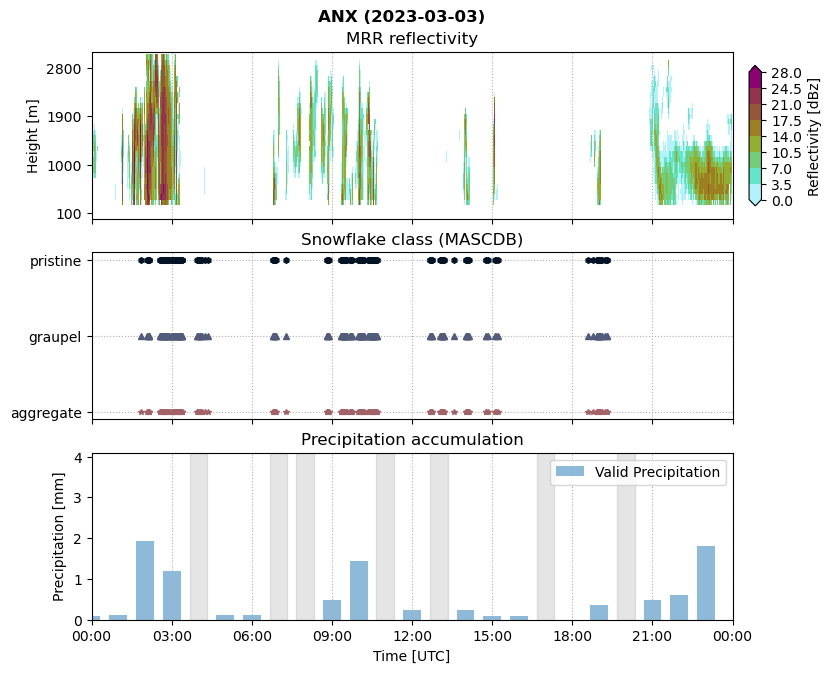

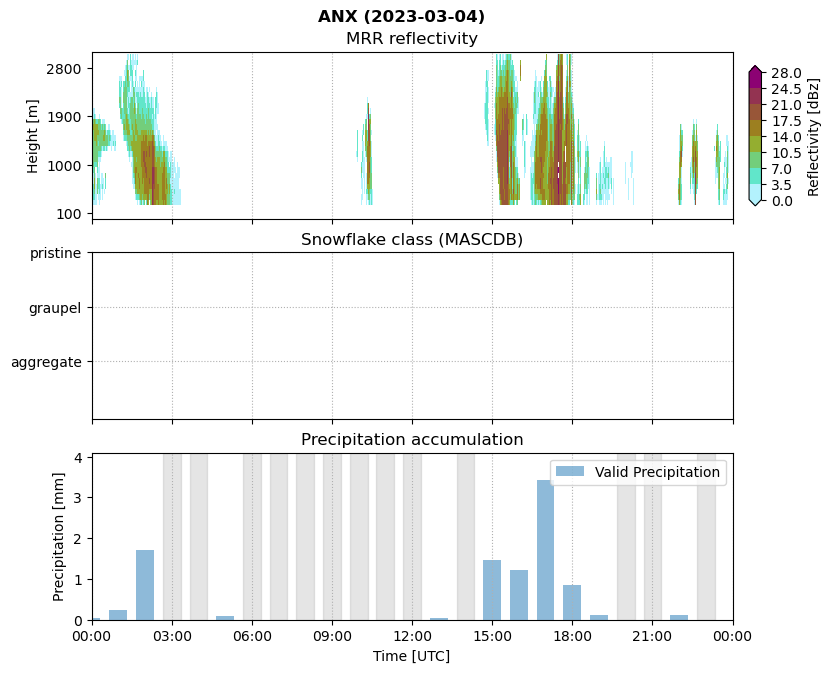

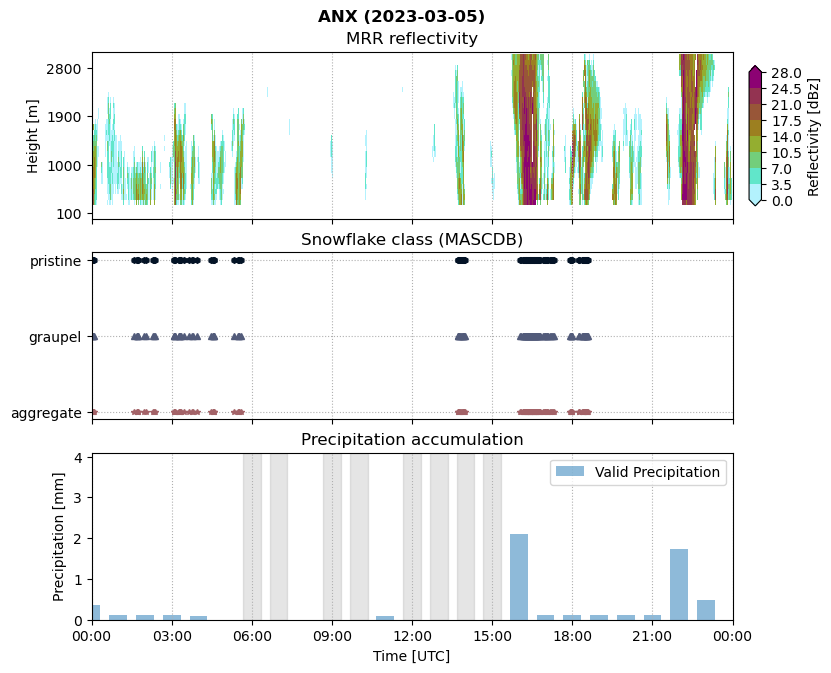

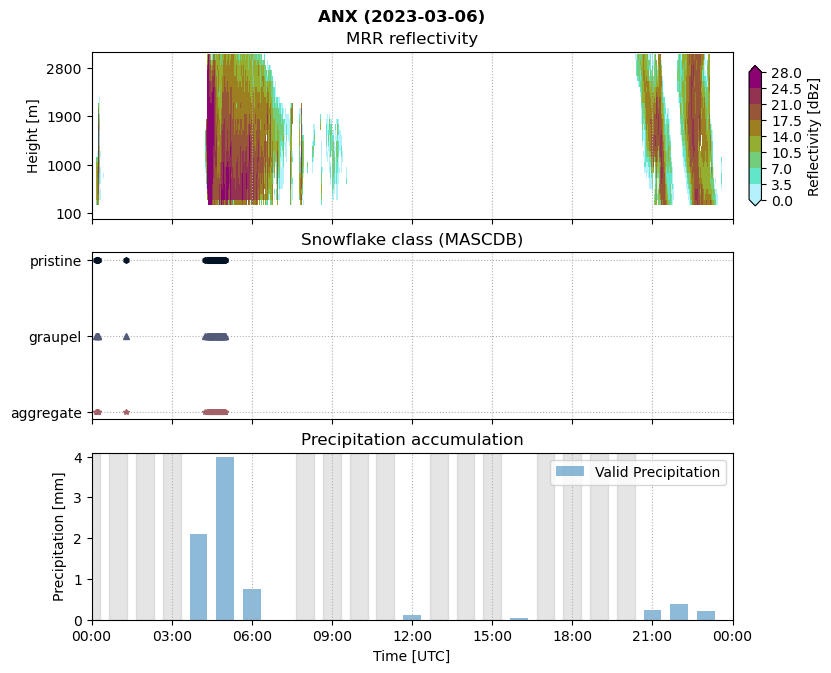

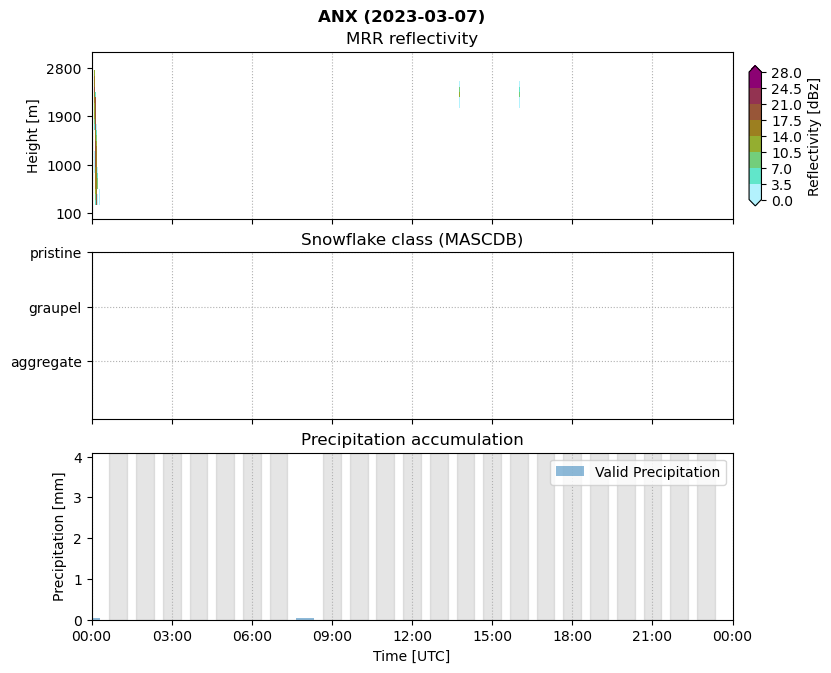

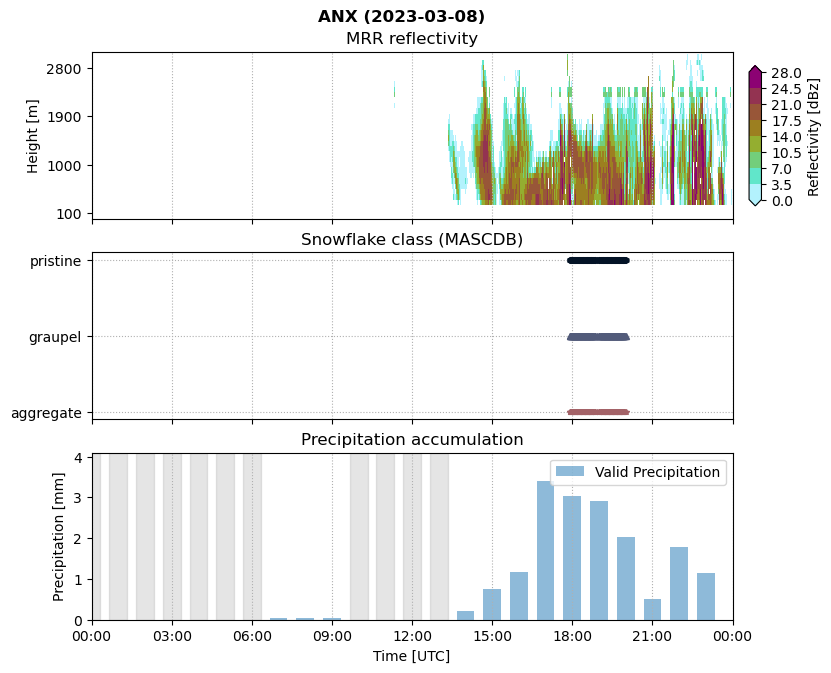

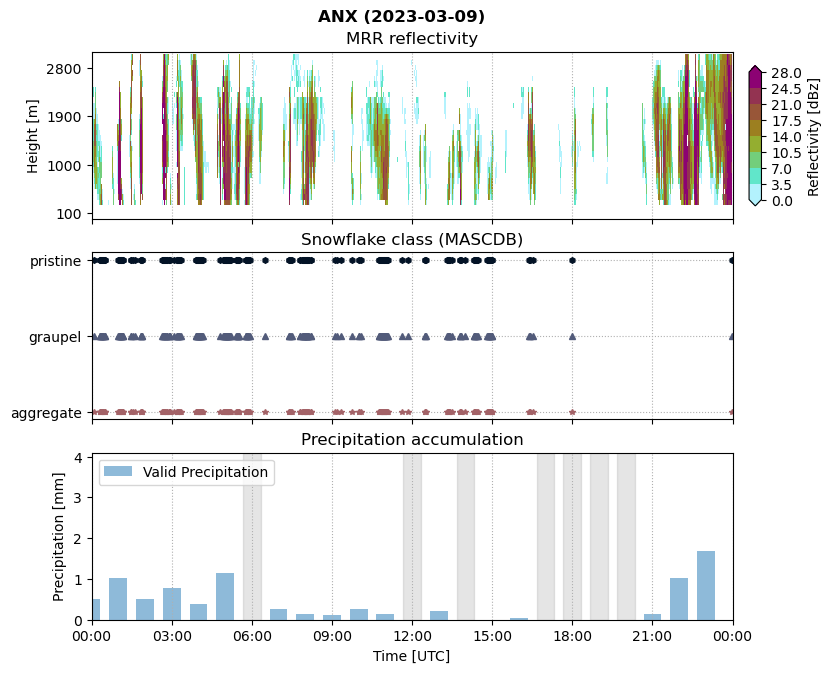

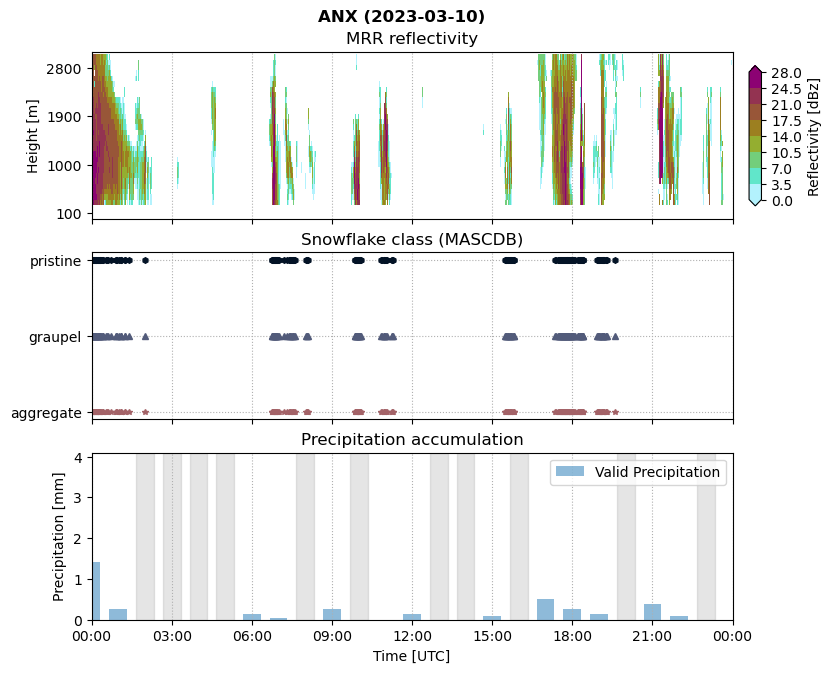

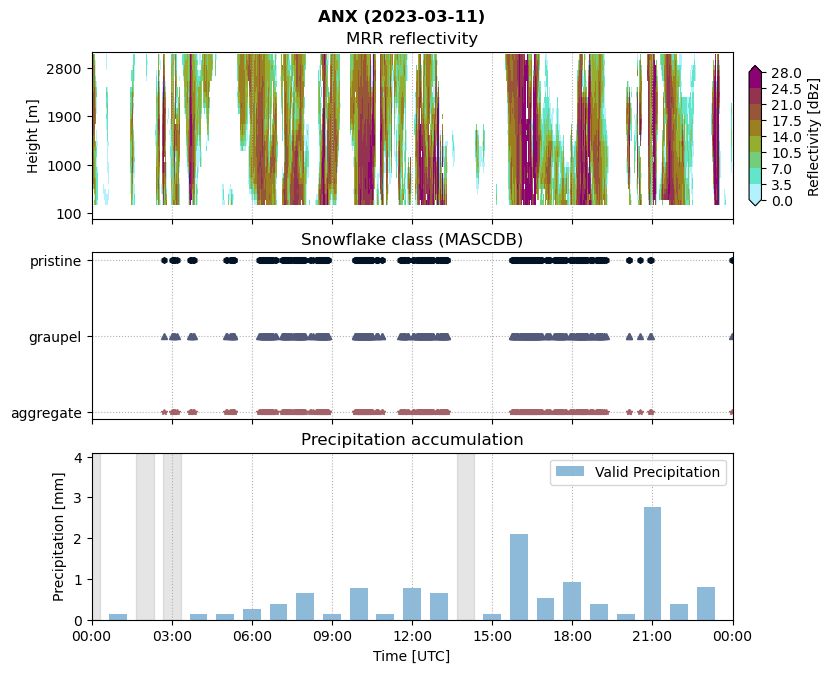

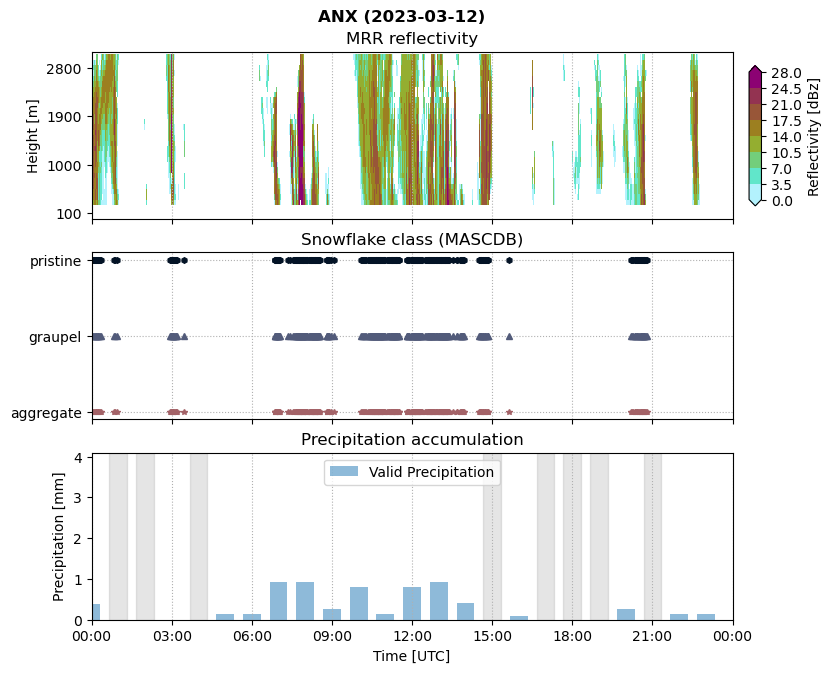

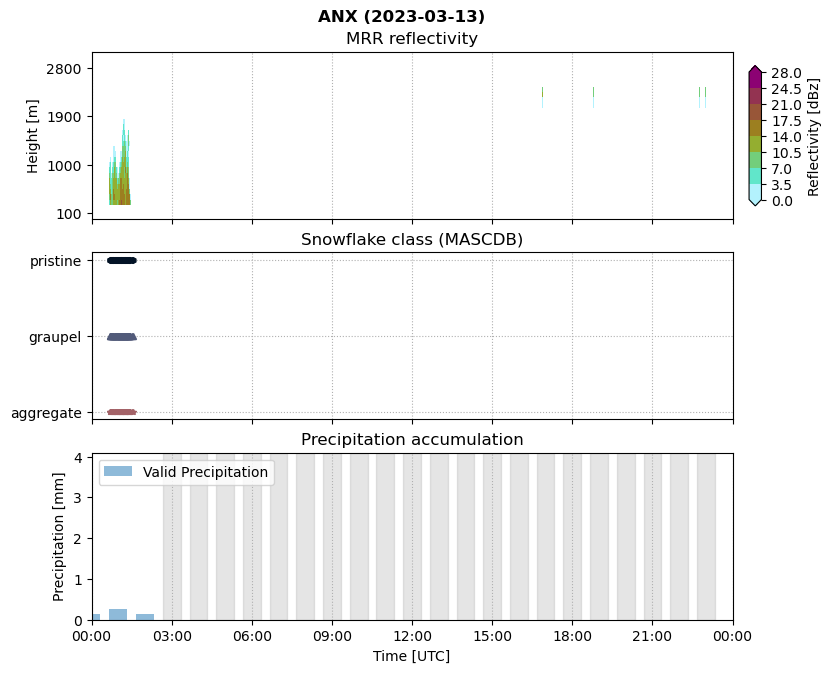

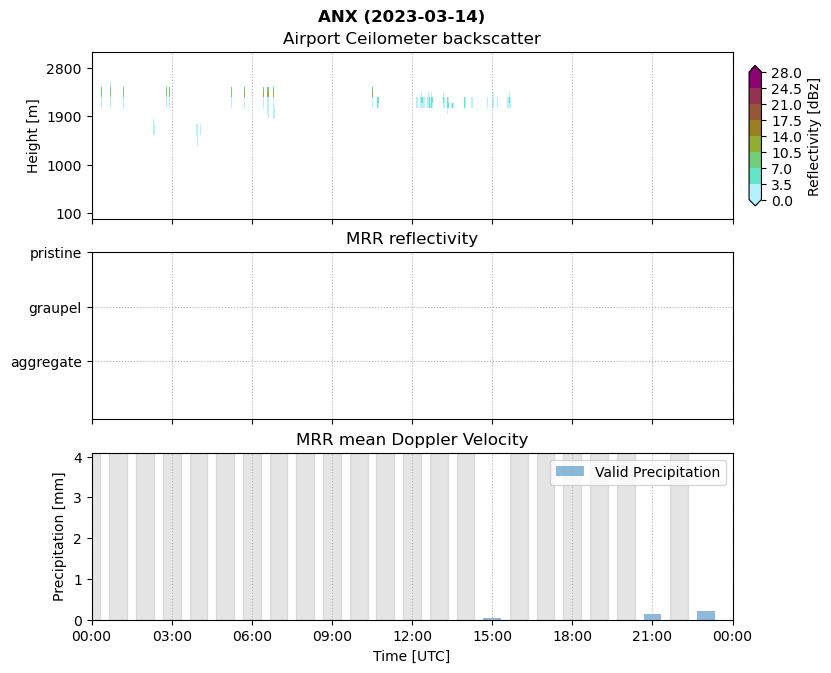

In [12]:
for day, ds_day in ds_23.groupby("time.date"):
    day_start = pd.Timestamp(f"{day} 00:00:00")
    day_end = day_start + pd.Timedelta(hours=23, minutes=59)
    _xmax = day_start + pd.Timedelta(hours=24)

    fct.plt_Ze_W_p_T_U(ds_day, day_start, _xmax, site)

    # save image to png
    plt.savefig(FIG_DIR + f'Ze_snowflake_class_precip_{site}_{day}.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

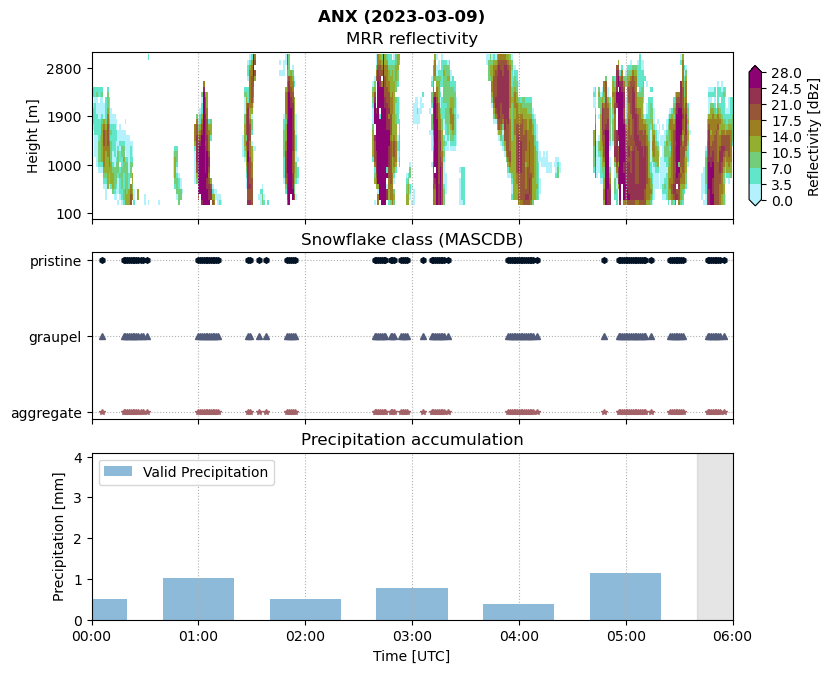

In [13]:
site='ANX'
date = '20230309'
day_start = pd.Timestamp(f"{date} 00:00:00")
day_end = day_start + pd.Timedelta(hours=23, minutes=59)
_xmax = day_start + pd.Timedelta(hours=6)


fct.plt_Ze_W_p_T_U(ds_23.sel(time=date), day_start, _xmax, site)
# save image to png
# plt.savefig(FIG_DIR + f'Ze_snowflake_class_precip_{site}_20230309.png', format='png', bbox_inches='tight', dpi=300, )#transparent=True,)

### Sum the retrieved precipitation amount between the changes in precipitation at the Geonor


In [14]:
df_sum = ds_23[['precipitation', 'Matrosov_aggregate', 'Bracci_aggregate', 'Nakai_aggregate', 'Nakai_graupel', 'Pu_graupel', 'Ze_linear']].sel(time=slice('2023-02-15', '2023-03-14')).to_dataframe()

In [15]:
df_mean = ds_23[['air_temperature', 'wind_direction', 'wind_speed', 'Ze_400m', ]].sel(time=slice('2023-02-15', '2023-03-14')).to_dataframe()

### Load the snowflake class names to find the dominant class within dTime change at the Geonor


In [16]:
sf_class = xr.open_dataset(os.path.join(INPUT_DATA_DIR, 'MASC_DB', 'Norway-2023_MASCDB_aggregate_graupel_pristine.nc'), decode_times=True)['snowflake_class_name'].to_series()

In [17]:
def test_and_return_dominant_sf_class(seg, sclass):
    # count the occurences of the snowflake class name within the dTime
    aggregate_count = seg.str.count('aggregate').sum()
    graupel_count = seg.str.count('graupel').sum()
    pristine_count = seg.str.count('pristine').sum()
    total_count = len(seg)

    # calculate the fraction of this number to find which snowflake class dominates within dTime
    frac_agg = aggregate_count/total_count
    frac_graupel = graupel_count/total_count
    frac_pris = pristine_count/total_count

    largest_number = max(frac_agg, frac_graupel, frac_pris)

    # assign dominant snowflake class to dTime if it occurs more than 60% 
    if largest_number >= 0.6:
        if largest_number == frac_agg:
            sclass.append('aggregate')
        elif largest_number == frac_graupel:
            sclass.append('graupel')
        elif largest_number == frac_pris:
            sclass.append('pristine')
    if largest_number < 0.6:
        sclass.append('mixed')
    return sclass

In [18]:
notna_idx = df_sum['precipitation'].dropna().index

sums = []
means = []
sclass = []
# First segment: from start → first non-NaN
sums.append(df_sum.loc[:notna_idx[0]].sum(numeric_only=True))
means.append(df_mean.loc[:notna_idx[0]].mean(numeric_only=True))
if len(sf_class.loc[:notna_idx[0]]) != 0:
    sclass = test_and_return_dominant_sf_class(sf_class.loc[:notna_idx[0]], sclass)
else:
    sclass.append(np.nan)

for i in range(len(notna_idx)-1):
    seg = df_sum.loc[notna_idx[i] + pd.Timedelta(minutes=1) : notna_idx[i+1]]
    seg_m = df_mean.loc[notna_idx[i] + pd.Timedelta(minutes=1) : notna_idx[i+1]]
    seg_sf = sf_class.loc[notna_idx[i] + pd.Timedelta(minutes=1) : notna_idx[i+1]]
    sums.append(seg.sum(numeric_only=True))
    means.append(seg_m.mean(numeric_only=True))

    if len(seg_sf) != 0:
        sclass = test_and_return_dominant_sf_class(seg_sf, sclass)
    else:
        sclass.append(np.nan)


    # 

    

In [19]:
df_corrected = pd.concat([pd.DataFrame(sums).set_index(notna_idx), pd.DataFrame(means).set_index(notna_idx), pd.DataFrame({"snowflake_class_name":sclass}).set_index(notna_idx)], axis=1)
df_corrected.rename(columns={"precipitation":"Geonor",}, inplace=True)

In [20]:
# Compute Z from linear sums
# Compute safely: return NaN for invalid values
df_corrected['Z_from_linear'] = df_corrected['Ze_linear'].apply(lambda y: 10 * np.log10(y) if y > 0 else np.nan)

In [21]:
## Convert snowfall increments to rate (mm/h)
# Calculate time difference in hours
df_corrected["delta_h"] = df_corrected.index.to_series().diff().dt.total_seconds() / 3600

# Convert to mm/h rate
df_corrected["rate_mm_h"] = df_corrected["Geonor"] / df_corrected["delta_h"]

In [23]:
for day, df_day in df_corrected.groupby(pd.Grouper(freq='D')):
    day = day.strftime('%Y%m%d')
    filename = f"Z_S_2Tm_WD_WS_class_{site}_{day}.nc"
    df_day.to_xarray().to_netcdf(os.path.join(nc_dir, filename))

In [27]:
nc_dir

'/mn/vann/franzihe/output/ANX_obs'

In [24]:
# Define start and end of window to exclude/include
start = pd.Timestamp("2023-03-09 00:00")
end = pd.Timestamp("2023-03-09 06:00")

# mask for rows outside the range
mask = (df_corrected.index < start) | (df_corrected.index > end)
# select all rows not in that window
df_exclude = df_corrected.loc[mask]

# mask for inside the range
mask = (df_corrected.index >= start) & (df_corrected.index <= end)
df_only = df_corrected.loc[mask]


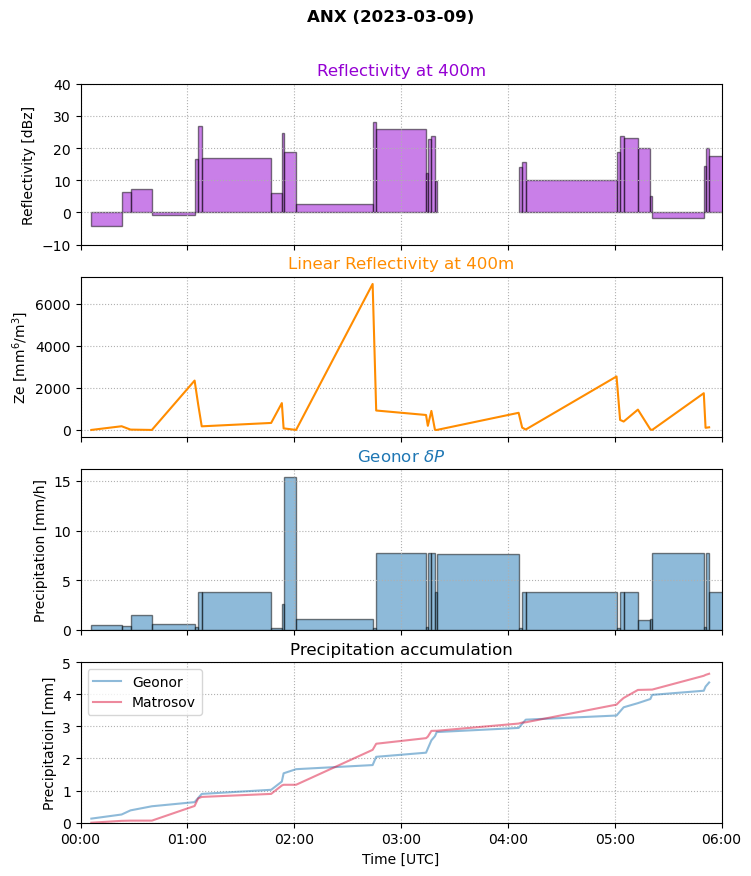

In [26]:
# fig, axsm = plt.subplots(3,1, figsize=(8.27, 7.014), sharex=True)
fig, axsm = plt.subplots(4,1, figsize=(8.27, 7.014/3*4), sharex=True)
axs= axsm.flatten()

# compute time differences in days
dt = df_only.index.to_series().diff().dt.total_seconds().div(86400)
# shift so each bar uses the NEXT delta as width
widths = dt.shift(-1).fillna(dt.mean())  # last one: fallback to mean width


# Reflectivity in dbz at 400m
# axs[0].scatter(df_only['Ze_400m'].index, df_only['Ze_400m'], color='darkviolet', s=5)
axs[0].bar(df_only['Z_from_linear'].index, df_only['Ze_400m'], width=widths, align='edge', color='darkviolet', edgecolor='black', alpha=0.5)
axs[0].set_ylabel(f"Reflectivity [{ds_23['Ze_400m'].attrs['units']}]")
axs[0].set_yticks(np.arange(-10,50,10))

# Reflectitivyt in linear units at 400m
axs[1].plot(df_only['Ze_linear'].index, df_only['Ze_linear'], color='darkorange', )#s=5)
# axs[1].bar(df_only['Ze_linear'].index, df_only['Ze_linear'], color='darkorange',  width=widths, align='edge', edgecolor='black', alpha=0.5)
axs[1].set_ylabel("Ze [mm${^6}$/m${^3}$]")
# axs[1].set_yscale('log')


# Precip at Geonor
# plot bar
axs[2].bar(df_only.index, df_only['rate_mm_h'], width=widths, align='edge', color='tab:blue', alpha=0.5, edgecolor="black")
axs[2].set_ylabel("Precipitation [mm/h]")

# cumsum at Geonor and from Matrosov
pg = df_only['Geonor'].cumsum()
axs[3].plot(pg.index, pg, color='tab:blue', alpha=0.5, label='Geonor')
pm = df_only['Matrosov_aggregate'].cumsum()
axs[3].plot(pm.index, pm, color='crimson', alpha=0.5, label='Matrosov')
axs[3].set_ylabel("Precipitatioin [mm]")
axs[3].set_ylim([0, 5])
axs[3].legend()

# Shared formatting
date_form = DateFormatter("%H:00")
for ax, title, color in zip(axs, ["Reflectivity at 400m", "Linear Reflectivity at 400m", "Geonor $\delta P$", "Precipitation accumulation"], ['darkviolet', 'darkorange', 'tab:blue', 'black']):
        ax.set(xlabel = "", )
        ax.set_title(title, color=color)
        ax.grid(ls=':')
        ax.tick_params(axis='x', labelrotation=0)
        plt.setp(ax.get_xticklabels(), horizontalalignment="center")
        ax.xaxis_date()
        ax.xaxis.set_major_formatter(date_form)
        ax.set_xlim([day_start, _xmax])

axs[-1].set(xlabel="Time [UTC]")
fig.suptitle(f"{site.split('.')[0]} ({df_only.index[0].date()})", fontweight="bold")
# fig.subplots_adjust(top=0.94)
fig.subplots_adjust(top=0.9)

# save image to png
figname= os.path.join(FIG_DIR, 'reflectivity_400m', f'refl_dbz_mm6m3_geonor_matrosov_{site}_{df_only.index[0].date()}.png')
# plt.savefig(figname, format='png', bbox_inches='tight', dpi=300, )#transparent=True,)

### Plot the Ze_linear to mm/h for the case and then fill in with the rest of the data. Then add Z-S relationship fit and the one from Matrosov

In [37]:
def model(x, a, b):
    return a * x**b

In [38]:
df_zs = df_corrected[["rate_mm/h", "Ze_linear"]].dropna()

In [49]:
logx

0      -3.055347
1       0.506215
2       1.892509
3       1.894316
4       2.586109
          ...   
1011   -2.324301
1012   -6.736492
1013   -3.767582
1014   -2.547283
1015   -1.465526
Length: 1016, dtype: float64

In [52]:
logy.dropna()

0       9.068329
1       9.507110
2       8.619620
3       8.549259
4       8.775672
          ...   
1007    5.130326
1008    5.781335
1009    5.749167
1010    5.434138
1011    6.044072
Length: 910, dtype: float64

In [ ]:
# Log-linear regressions ln(y) = ln(a) + b*ln(x) --> gives a straight line
logx = (np.where(df_zs["rate_mm/h"] >0, np.log(df_zs["rate_mm/h"]), np.nan))#np.log(df_zs["rate_mm/h"])
logy = (np.where(df_zs['Ze_linear'] >0, np.log(df_zs['Ze_linear']), np.nan)) #np.log(df_zs["Ze_linear"])

# Drop rows where either logx or logy is Nan
valid = (~logx.isnan())

# Linear regression on log-log data
b2, loga = np.polyfit(logx, logy, 1)
a2 = np.exp(loga)

print(f"Fit: Z = {a2:.3f} * S^{b2:.3f}")

# Nonlinear curve fitting 
# the curve fitting is done with an iterative nonlinear optimization. The optimizer starts at the guess p0, then tries to minimize the squared error between the model and the data. A good initial guess helps the optimizer converge quickly and to get the right solution. 
# From the log-linear regression we get a quick estimate of a and b, that's why we use those as p0
params, cov = curve_fit(model, df_zs['rate_mm/h'], df_zs['Ze_linear'], p0=(a2,b2))
a, b = params
print(f"Fit: Z = {a:.3f} * S^{b:.3f}")

Fit: Z = nan * S^nan
Fit: Z = nan * S^nan


/tmp/ipykernel_204253/3137227334.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  params, cov = curve_fit(model, df_zs['rate_mm/h'], df_zs['Ze_linear'], p0=(a2,b2))


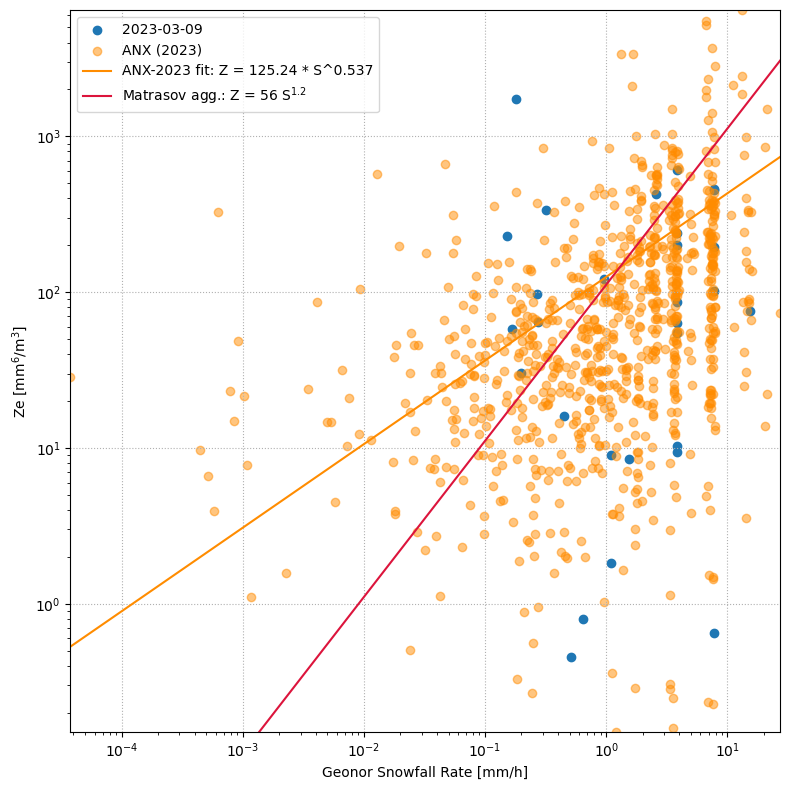

In [44]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(x=df_only['rate_mm/h'], y=df_only['Ze_linear'], color='tab:blue', label=f"{df_only.index[0].date()}")
ax.scatter(x=df_exclude['rate_mm/h'], y=df_exclude['Ze_linear'], color='darkorange', alpha=0.5, label=f"{site.split('.')[0]} (2023)")

# Plot trend line non-linear
x_smooth = np.linspace(df_corrected['rate_mm/h'].min(), df_corrected['Ze_linear'].max(),200)
y_smooth = model(x_smooth, a, b)
ax.plot(x_smooth, y_smooth, color='darkorange', label=f"ANX-2023 fit: Z = {a:.2f} * S^{b:.3f}")


# Generate line for Matrosov
xfit = np.linspace(df_corrected["Matrosov_aggregate"].min(), df_corrected["Ze_linear"].max(), 200)
yfit = model(xfit, 56, 1.2)
plt.plot(xfit, yfit, color='crimson', label="Matrasov agg.: Z = 56 S$^{1.2}$")

# Set labels and title
ax.set_xlabel('Geonor Snowfall Rate [mm/h]')
ax.set_ylabel("Ze [mm$^{6}$/m$^{3}$]")
ax.grid(True, ls=':')
ax.set_yscale('log')
ax.set_xscale('log')
ax.legend()

ax.set_xlim(df_corrected['rate_mm/h'].min(), df_corrected['rate_mm/h'].max())
ax.set_ylim(df_corrected['Ze_linear'].min(), df_corrected['Ze_linear'].max())

plt.tight_layout()

figname = os.path.join(FIG_DIR, 'snowfall_rate', 'Z_S_2023_fit_matrosov.png')
plt.savefig(figname, format='png', bbox_inches='tight', dpi=300) # transparent=True,

'/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/reflectivity_400m/refl_dbz_mm6m3_ANX_2023-03-09.png'

NameError: name 'date2num' is not defined

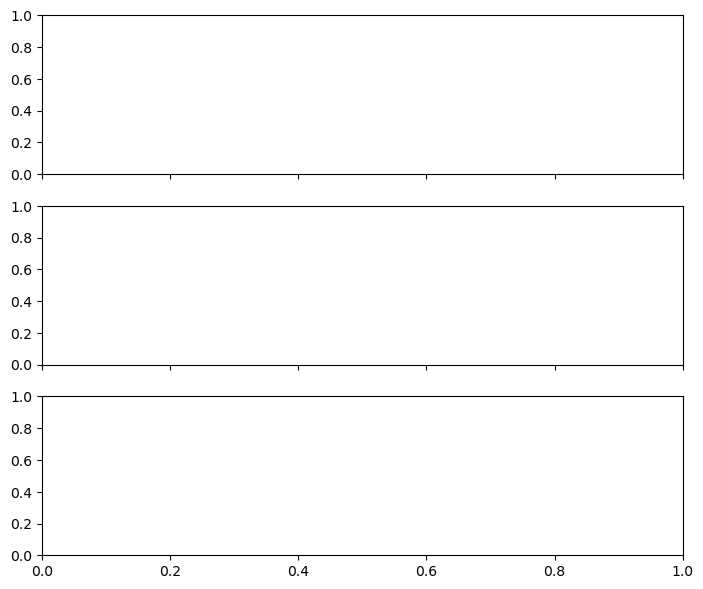

In [ ]:
## Bin averaging
        # create new dataset with time resolution 1 minute to
        _time = pd.date_range(day_start, periods=1440, freq="min").strftime('%Y-%m-%dT%H:%M:%S')
        dsm = xr.Dataset(data_vars=dict(
                                        air_temperature=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        wind_direction=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        wind_speed=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        precipitation=(["time"], da.full(shape= (len(_time),), fill_value = np.nan)),
                                        Ze=(["time","range"], da.full(shape= (len(_time),len(dsx.range[1:-1][::2])), fill_value = np.nan)),
                                        W=(["time","range"], da.full(shape= (len(_time),len(dsx.range[1:-1][::2])), fill_value = np.nan)),
                                        height=(["time","range"], da.full(shape= (len(_time),len(dsx.range[1:-1][::2])), fill_value = np.nan)),
                                        spectralWidth=(["time","range"], da.full(shape= (len(_time),len(dsx.range[1:-1][::2])), fill_value = np.nan)),),
                        coords=dict(time=_time, range=dsx.range[1:-1][::2].values))
        # assign variables and attributes to the dataset
        dsm['time'] = pd.to_datetime(dsm.time)

        # averaged values for each bin, return dataset
        dsm = fct.MRR_bin_averaged_dataset(dsx, dsm)

        # add MetNo data to dataset
        dsm['air_temperature'] = dsx['air_temperature']
        dsm['wind_direction'] = dsx['wind_direction']
        dsm['wind_speed'] = dsx['wind_speed']
        # dsm['precipitation'] = dsx['precipitation']


        fct.plt_Ze_W_p_T_U(dsm, day_start, _xmax, key)
        # save image to png
        plt.savefig(FIG_DIR + 'bin_avg_{}'.format(figname), format='png', bbox_inches='tight', transparent=True)

        # rename variables to indicate mean values
        dsm = dsm.rename({'range':'mean_range', 'Ze':'Ze_mean', 'W':'W_mean', 'height':'height_mean', 'spectralWidth':'spectralWidth_mean'})
        ###########################################################

        # merge original dataset with mean dataset
        dsx = dsx.merge(other=dsm, fill_value=np.nan, combine_attrs='no_conflicts')        


        # print("writing...", file_out)
        # dsx.to_netcdf(file_out)


In [ ]:
## Create TinyTag Temperature files with same time res as MRR data
# ds = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, 'MRR_islas/bin_averaged/*'))))['time']
# ds_T = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, 'islas_met_obs/*'))))
# years 
# months=['03']
# days=np.arange(18,22)
# years, months, days


# for day in days:
#     time = '{}-{}-{}'.format(years[0], months[0], day)
#     print(time)
    
#     TA = ds_T['TA'].where(ds.sel(time=time))
    
#     TA2 = TA.interp(time=ds.sel(time=time))
    
#     TA.plot()
#     TA2.plot()
    
#     TA2.to_netcdf('TinyTag_T_ISLAS{}{}{}.nc'.format(years[0], months[0], day))


In [ ]:
# rsync -a --progress franzihe@mimi.uio.no:/uio/kant/geo-metos-u1/franzihe/Documents/Figures/mrr_reflectivity /uufs/chpc.utah.edu/common/home/u6030275/public_html/Figures

In [ ]:
# rsync -av --progress franzihe@mimi.uio.no:/scratch/franzihe/output/MRR_islas /uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data/


In [ ]:
# rsync -a --progress login.nird.sigma2.no:/projects/NS9600K/sldam/timelapses_islas2022 /home/franzihe/Documents/Figures

In [ ]:
# files = sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110/*')))
# # metno = xr.open_dataset('/scratch/franzihe/input/Met-No_obs/SN87110/sum(precipitation_amount PT1H)_202203.nc')
# metno = xr.open_mfdataset(files)

# f, ax = plt.subplots(figsize=[3.18, 5.25], ) 
# (metno.sel(time='2022-04-01')['sum(precipitation_amount PT1H)'].cumsum(dim='time') - metno.sel(time='2022-04-01')['sum(precipitation_amount PT1H)'].isel(time=0)).plot.line(ax =ax, x='time', 
#                                                                                             ylim=[0,20], 
#                                                                                             xlim=['2022-04-01T00:00:00.000000000', '2022-04-02T00:00:00.000000000'],
#                                                                                             label='MetNo obs',add_legend=True)

# # plot legend
# ax.legend(loc='upper right')
# ax.set_ylabel('', )#fontsize = 10.0) # Y label
# ax.set_xlabel('', )#fontsize = 10) # X label

# ax.set_xticklabels([])
# ax.set_yticklabels([])
# ax.grid(True)

# plt.savefig('demo.png', transparent=True)